# Track 1 — 1D Toy Problem: Setup (Data-Generating Process & Model Family)

**Thesis:** *End-to-End Calibration: Theory and Empirical Evaluation in Biomedical Context*

**Track 1** — fully synthetic 1D binary classification with a known true posterior $\eta(x)$.

This notebook builds and sanity-checks the two pieces every later Track 1 notebook will import:

1. The data-generating process (DGP).
2. The overparameterised logistic Legendre-basis model family.
3. The approximation-quality diagnostic, Figure 1-A.

Everything here is saved to a small local module (`track1_core.py`) so that later notebooks (Q1.1/Q1.2 training dynamics, reliability diagrams, post-hoc calibration, etc.) can just `import` it instead of re-defining these functions.

**Colab note:** this notebook is self-contained — running the first code cell will write `track1_core.py` to the local runtime, so no upload step is needed.


## 0. Imports and global config

In [ ]:
import numpy as np
from scipy.special import eval_legendre
from numpy.polynomial.legendre import leggauss
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator, LogLocator

# Colour palette used consistently across all Track 1 notebooks
PALETTE = {
    "eta": "#264653",       # true posterior
    "train": "#e76f51",     # training points
    "test": "#8ab17d",
    "penalty_low": "#2a9d8f",
    "penalty_high": "#e9c46a",
    "basis": ["#264653", "#2a9d8f", "#e9c46a", "#f4a261", "#e76f51", "#8ab17d"],
    "capacity": {10: "#264653", 100: "#e9c46a", 1000: "#e76f51"},  # primary m values
}

plt.rcParams.update({
    "font.family": "STIXGeneral",
    "mathtext.fontset": "stix",
    # "font.family": "serif",
    # "font.serif": ["Computer Modern Roman", "CMU Serif"],
    # "mathtext.fontset": "cm",
    "font.size": 12,
    "axes.labelsize": 13,
    "axes.titlesize": 13,
    "figure.titlesize": 14,
    "figure.titleweight": "bold",
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "figure.dpi": 120,
    "savefig.dpi": 300,
    # "savefig.bbox": "tight",
    # "savefig.pad_inches": 0.05,
    "savefig.format": "pdf"
})

np.set_printoptions(precision=4, suppress=True)

## 1. Data-Generating Process (§1.1)

$$
X \sim \mathrm{Uniform}[-1, 1], \qquad Y \mid X = x \sim \mathrm{Bernoulli}(\eta(x)),
\qquad \eta(x) = 0.1 + 0.8\,\sigma\!\big(4\sin(\pi x)\big)
$$

- **Train set:** $n_{\text{train}} = 100$ (deliberately small, to induce overparameterisation
  pressure). Regenerated per seed.
- **Test set:** $n_{\text{test}} = 50{,}000$, generated with **one fixed seed** so it is the
  same across all 30 runs (comparability).
- 30 random seeds total (data seed and initialisation seed kept separate).


In [ ]:
def true_eta(x):
    '''True posterior P(Y=1 | X=x) = 0.1 + 0.8 * sigmoid(4 sin(pi x)). x in [-1, 1].'''
    x = np.asarray(x, dtype=np.float64)
    return 0.1 + 0.8 / (1.0 + np.exp(-4.0 * np.sin(np.pi * x)))


def generate_data(n, seed):
    '''
    X ~ Uniform[-1, 1], Y | X = x ~ Bernoulli(eta(x)).
    Returns (X, Y), each shape (n,), Y in {0., 1.}.
    '''
    rng = np.random.default_rng(seed)
    X = rng.uniform(-1.0, 1.0, size=n)
    Y = rng.binomial(1, true_eta(X)).astype(np.float64)
    return X, Y


# Fixed test set used by every notebook / every seed in Track 1
TEST_SEED = 999
N_TEST = 50_000
X_test, Y_test = generate_data(n=N_TEST, seed=TEST_SEED)
print(f"Test set: X shape={X_test.shape}, Y shape={Y_test.shape}, "
      f"positive rate={Y_test.mean():.3f}")

Test set: X shape=(50000,), Y shape=(50000,), positive rate=0.501


### Sanity check — does the sampler actually match $\eta(x)$?

We generate a large pooled sample, bin by $x$, and compare the empirical positive rate per
bin against the analytic $\eta(x)$ at the bin centre. This is a check on the DGP code, not an
experiment result.

In [ ]:
X_big, Y_big = generate_data(n=200_000, seed=0)

bins = np.linspace(-1, 1, 21)
bin_idx = np.clip(np.digitize(X_big, bins) - 1, 0, len(bins) - 2)
bin_centers = 0.5 * (bins[:-1] + bins[1:])
emp_rate = np.array([
    Y_big[bin_idx == b].mean() if np.any(bin_idx == b) else np.nan
    for b in range(len(bins) - 1)
])
true_rate = true_eta(bin_centers)
max_abs_err = np.nanmax(np.abs(emp_rate - true_rate))
print(f"max |empirical rate - eta(x)| across 20 bins (n=200,000): {max_abs_err:.4f}")
assert max_abs_err < 0.02, "empirical rate deviates too much from eta(x) -- check the DGP"
print("OK: sampler matches the analytic posterior within tolerance.")

max |empirical rate - eta(x)| across 20 bins (n=200,000): 0.0106
OK: sampler matches the analytic posterior within tolerance.


### Sanity check — reproducibility of seeds

Data seed and (later) initialisation seed must be independent, and the same data seed must always reproduce the same draw.


In [ ]:
X_tr, Y_tr = generate_data(n=100, seed=1)
X_tr_again, _ = generate_data(n=100, seed=1)
X_tr_other_seed, _ = generate_data(n=100, seed=2)

assert np.allclose(X_tr, X_tr_again), "same seed must reproduce the same draw"
assert not np.allclose(X_tr, X_tr_other_seed), "different seeds must give different draws"
assert X_tr.shape == (100,) and Y_tr.shape == (100,)
print("OK: train-set generation is reproducible and seed-sensitive as expected.")

OK: train-set generation is reproducible and seed-sensitive as expected.


### Visual check: true posterior + one training draw

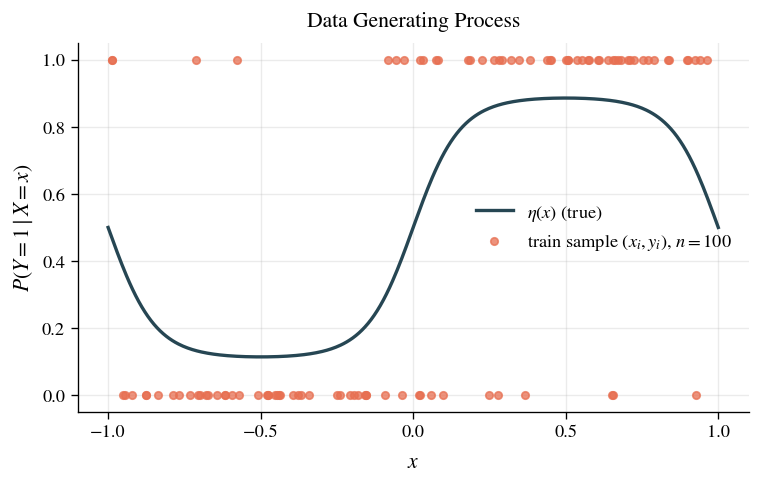

In [ ]:
x_grid = np.linspace(-1, 1, 400)

fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.plot(x_grid, true_eta(x_grid), color=PALETTE["eta"], lw=2.0, label=r"$\eta(x)$ (true)")
ax.scatter(X_tr, Y_tr, color=PALETTE["train"], s=20, alpha=0.75, zorder=3,
           label=r"train sample $(x_i, y_i)$, $n=100$")
ax.set_xlabel("$x$", labelpad=7)
ax.xaxis.set_major_locator(MultipleLocator(0.5))
ax.set_ylabel(r"$P(Y=1 \mid X=x)$", labelpad=4)
ax.set_title("Data Generating Process", pad=10)
ax.legend(frameon=False, loc="right")
ax.tick_params(axis="both", which="major", length=4, width=0.8)
fig.tight_layout()

fig.savefig("Figure_1_data_generating_process.pdf", format="pdf", bbox_inches="tight")
plt.show()

## 2. Model Family — Overparameterised Logistic Basis Model

$$
p_\theta(x) = \sigma\!\Big(\sum_{k=0}^{m} \theta_k\, \phi_k(x)\Big),
\qquad \phi_0, \dots, \phi_m = \text{Legendre polynomials on } [-1, 1]
$$

Capacity sweep on the polynomial degree $m$:

| Regime | $m$ | $r$ |
|---|---|---|
| Under-parameterized | 5, 10 | ≈ 0.35 - 0.50 |
| Interpolation threshold ($m \approx n_{\text{train}}$) | 100 | 1 |
| Near-threshold over-parameterized | 120, 200, 300 | ≈ 1.04 - 1.24 |
| Stronngly over-parametrized | 1000 | ≈ 1.5 |

**Primary comparison points: $m \in \{10, 100, 1000\}$**  — under-parameterised, exactly at the interpolation threshold, and strongly overparameterised.

Initialisation: $\theta \sim \mathcal{N}(0, 0.01)$, with the init seed kept separate from the data seed.

### Can the model class recover $\eta(x)$?

Since $\sigma$ is a continuous, strictly-increasing bijection onto $(0,1)$ and
$\eta(x) = 0.1 + 0.8\,\sigma(4\sin \pi x) \in (0.1, 0.9)$ is bounded away from 0 and 1, the
transformed function $g(x) = \sigma^{-1}(\eta(x))$ is continuous and bounded on $[-1,1]$. By the
Weierstrass approximation theorem, $g$ can be uniformly approximated by polynomials of increasing
degree, and since $\sigma$ is uniformly continuous, $\sigma(P_m(x)) \to \eta(x)$ uniformly as
$m \to \infty$. So the model class can recover $\eta(x)$ arbitrarily well in the limit — Legendre
polynomials are just a numerically well-conditioned basis for the same polynomial space monomials
would span. Section 4 below checks *how fast* this convergence actually is, which matters for
interpreting later results at the primary capacities.

In [ ]:
def legendre_design_matrix(x, m):
    '''
    Design matrix Phi, shape (n, m+1), columns phi_0(x)...phi_m(x).
    Built via the three-term recurrence (2k-1)*x*P_{k-1}(x) - (k-1)*P_{k-2}(x) = k*P_k(x),
    i.e. O(n*m) instead of calling scipy.special.eval_legendre once per degree (O(n*m^2)).
    At m=1000 this matters a lot: the naive per-degree approach took 113s to build the
    (50000, 1001) test-set design matrix; this version takes ~2.4s and matches scipy exactly.
    '''
    x = np.asarray(x, dtype=np.float64)
    # return np.stack([eval_legendre(k, x) for k in range(m + 1)], axis=1)
    n = x.shape[0]
    Phi = np.empty((n, m + 1), dtype=np.float64)
    Phi[:, 0] = 1.0
    if m >= 1:
        Phi[:, 1] = x
    for k in range(2, m + 1):
        Phi[:, k] = ((2 * k - 1) * x * Phi[:, k - 1] - (k - 1) * Phi[:, k - 2]) / k
    return Phi


def sigmoid(z):
    z = np.clip(z, -500, 500)  # avoid overflow in exp
    return 1.0 / (1.0 + np.exp(-z))


def init_theta(m, seed):
    '''theta ~ N(0, 0.01), independent of the data seed.'''
    rng = np.random.default_rng(seed)
    return rng.normal(loc=0.0, scale=np.sqrt(0.01), size=m + 1)


def model_predict(theta, Phi):
    '''p_theta(x) = sigmoid(Phi @ theta).'''
    return sigmoid(Phi @ theta)


CAPACITY_GRID = [5, 10, 100, 120, 200, 300, 1000]
PRIMARY_CAPACITIES = [10, 100, 1000]
INIT_SCALE = np.sqrt(0.01)

### Sanity check — correctness of the fast recurrence vs. scipy's `eval_legendre`

Since the design-matrix builder changed for performance reasons, first confirm it still computes
the same values as the trusted scipy reference (on a smaller case, where the slow version is
still fast enough to serve as ground truth).

In [ ]:
X_small = np.random.default_rng(7).uniform(-1, 1, 200)
Phi_ref = np.stack([eval_legendre(k, X_small) for k in range(51)], axis=1)
Phi_fast = legendre_design_matrix(X_small, 50)

max_diff = np.max(np.abs(Phi_ref - Phi_fast))
print(f"max abs difference vs. scipy.special.eval_legendre (m=50): {max_diff:.2e}")
assert max_diff < 1e-9
print("OK: recurrence-based design matrix matches scipy exactly.")

max abs difference vs. scipy.special.eval_legendre (m=50): 4.72e-15
OK: recurrence-based design matrix matches scipy exactly.


### Sanity check — shapes and output range across the full capacity sweep

In [ ]:
import time

for m in CAPACITY_GRID:
    t0 = time.time()
    Phi_tr = legendre_design_matrix(X_tr, m)
    build_time = time.time() - t0
    theta0 = init_theta(m, seed=42)
    preds = model_predict(theta0, Phi_tr)

    assert Phi_tr.shape == (100, m + 1)
    assert theta0.shape == (m + 1,)
    assert preds.shape == (100,)
    assert np.all((preds > 0) & (preds < 1)), "sigmoid output must lie strictly in (0, 1)"
    assert np.all(np.isfinite(Phi_tr)), f"non-finite basis values at m={m}"
    assert np.max(np.abs(Phi_tr)) <= 1.0 + 1e-9, "Legendre polynomials must stay bounded by 1 on [-1,1]"

    print(f"m={m:>4}:  Phi shape={Phi_tr.shape},  build={build_time*1000:.1f}ms,  "
          f"pred range=({preds.min():.3f}, {preds.max():.3f})")

m=   5:  Phi shape=(100, 6),  build=0.2ms,  pred range=(0.466, 0.547)
m=  10:  Phi shape=(100, 11),  build=0.2ms,  pred range=(0.464, 0.551)
m= 100:  Phi shape=(100, 101),  build=1.4ms,  pred range=(0.432, 0.582)
m= 120:  Phi shape=(100, 121),  build=5.3ms,  pred range=(0.422, 0.585)
m= 200:  Phi shape=(100, 201),  build=3.9ms,  pred range=(0.411, 0.582)
m= 300:  Phi shape=(100, 301),  build=12.9ms,  pred range=(0.414, 0.590)
m=1000:  Phi shape=(100, 1001),  build=36.8ms,  pred range=(0.416, 0.600)


### Sanity check — near-uniform predictions at initialisation

With $\theta \sim \mathcal{N}(0, 0.01)$ the pre-activations are small, so predictions should
start close to 0.5 even for the largest model ($m=1000$).

In [ ]:
Phi_tr_1000 = legendre_design_matrix(X_tr, 1000)
theta0_1000 = init_theta(1000, seed=42)
preds0_1000 = model_predict(theta0_1000, Phi_tr_1000)

print(f"m=1000 init predictions: mean={preds0_1000.mean():.4f}, std={preds0_1000.std():.4f}, "
      f"range=({preds0_1000.min():.4f}, {preds0_1000.max():.4f})")
assert abs(preds0_1000.mean() - 0.5) < 0.05, "initial predictions should be close to 0.5"
print("OK: initialisation gives near-uniform predictions, as intended.")

m=1000 init predictions: mean=0.5080, std=0.0412, range=(0.4162, 0.5995)
OK: initialisation gives near-uniform predictions, as intended.


### Visual check: first few Legendre basis functions

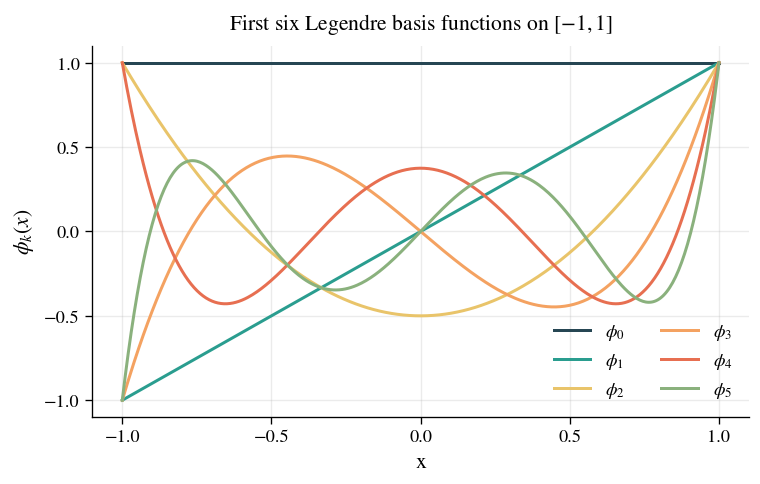

In [ ]:
fig, ax = plt.subplots(figsize=(6.5, 4.2))
for k in range(6):
    ax.plot(x_grid, eval_legendre(k, x_grid), color=PALETTE["basis"][k], lw=1.8,
            label=fr"$\phi_{{{k}}}$")
ax.set_xlabel("x", labelpad=4)
ax.set_ylabel(r"$\phi_k(x)$", labelpad=5)
ax.xaxis.set_major_locator(MultipleLocator(0.5))
ax.yaxis.set_major_locator(MultipleLocator(0.5))
# ax.set_ylim(-1.1, 1.1)
ax.set_title("First six Legendre basis functions on $[-1, 1]$", pad=10)
ax.legend(frameon=False, ncol=2, loc="best")
ax.tick_params(axis="both", which="major", length=4, width=0.8)
fig.tight_layout()

fig.savefig("Figure_1_legendre_basis_functions.pdf", format="pdf", bbox_inches="tight")
plt.show()

## 3. Export core utilities as a reusable module

Later Track 1 notebooks (training dynamics, reliability diagrams, post-hoc calibration, ...)
will `import track1_core as t1` rather than redefining these functions. Run the cell below to
write it to the Colab runtime's local filesystem.


In [ ]:
%%writefile track1_core.py
'''
Track 1 core utilities: data-generating process + Legendre basis model.
Auto-generated from Notebook 1 (Setup). Import this in later Track 1 notebooks.
'''
import numpy as np

TEST_SEED = 999
N_TEST = 50_000
CAPACITY_GRID = [5, 10, 100, 120, 200, 300, 1000]
PRIMARY_CAPACITIES = [10, 100, 1000]
INIT_SCALE = np.sqrt(0.01)

PALETTE = {
    "eta": "#264653",
    "train": "#e76f51",
    "test": "#8ab17d",
    "penalty_low": "#2a9d8f",
    "penalty_high": "#e9c46a",
    "basis": ["#264653", "#2a9d8f", "#e9c46a", "#f4a261", "#e76f51", "#8ab17d"],
    "capacity": {10: "#264653", 100: "#e9c46a", 1000: "#e76f51"},
}


def true_eta(x):
    '''True posterior P(Y=1 | X=x) = 0.1 + 0.8 * sigmoid(4 sin(pi x)). x in [-1, 1].'''
    x = np.asarray(x, dtype=np.float64)
    return 0.1 + 0.8 / (1.0 + np.exp(-4.0 * np.sin(np.pi * x)))


def generate_data(n, seed):
    '''X ~ Uniform[-1, 1], Y | X = x ~ Bernoulli(eta(x)). Returns (X, Y), shape (n,) each.'''
    rng = np.random.default_rng(seed)
    X = rng.uniform(-1.0, 1.0, size=n)
    Y = rng.binomial(1, true_eta(X)).astype(np.float64)
    return X, Y


def get_fixed_test_set():
    '''The single fixed test set shared across all seeds/notebooks (n=50,000, seed=999).'''
    return generate_data(n=N_TEST, seed=TEST_SEED)


def legendre_design_matrix(x, m):
    '''
    Design matrix Phi, shape (n, m+1), columns phi_0(x)...phi_m(x).
    Three-term recurrence, O(n*m). Do NOT replace with a per-degree eval_legendre loop --
    that is O(n*m^2) and takes ~113s at m=1000 on a 50,000-point test set vs. ~2.4s here.
    '''
    x = np.asarray(x, dtype=np.float64)
    # return np.stack([eval_legendre(k, x) for k in range(m + 1)], axis=1)
    n = x.shape[0]
    Phi = np.empty((n, m + 1), dtype=np.float64)
    Phi[:, 0] = 1.0
    if m >= 1:
        Phi[:, 1] = x
    for k in range(2, m + 1):
        Phi[:, k] = ((2 * k - 1) * x * Phi[:, k - 1] - (k - 1) * Phi[:, k - 2]) / k
    return Phi


def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1.0 / (1.0 + np.exp(-z))


def init_theta(m, seed):
    '''theta ~ N(0, 0.01), independent of the data seed.'''
    rng = np.random.default_rng(seed)
    return rng.normal(loc=0.0, scale=INIT_SCALE, size=m + 1)


def model_predict(theta, Phi):
    '''p_theta(x) = sigmoid(Phi @ theta).'''
    return sigmoid(Phi @ theta)

Writing track1_core.py


In [ ]:
# Reload check: import the freshly written module and re-run one sanity check from it
import importlib
import track1_core as t1
importlib.reload(t1)

Xc, Yc = t1.generate_data(n=100, seed=1)
assert np.allclose(Xc, X_tr), "track1_core.generate_data must match the in-notebook version"
Phi_check = t1.legendre_design_matrix(X_small, 50)
assert np.allclose(Phi_check, Phi_ref, atol=1e-9), "track1_core's design matrix must match scipy too"
print("OK: track1_core.py exports match the tested in-notebook functions.")
print("\nContents of track1_core.py are ready for import in later Track 1 notebooks.")

OK: track1_core.py exports match the tested in-notebook functions.

Contents of track1_core.py are ready for import in later Track 1 notebooks.


## 4. Figure 1-A — Legendre approximation error of $\sigma(P_m(x))$ vs. $\eta(x)$

We plan to confirm our largest $m$ is actually in the bias≈0 regime before
we attribute any remaining miscalibration to overfitting/variance rather than basis truncation."*

This uses **noiseless data only** — no training, no labels, just a direct least-squares (Legendre) projection of $g(x) = \sigma^{-1}(\eta(x))$, evaluated at the population level via high-order Gauss–Legendre quadrature rather than any finite training sample.

For each degree $m$: we project $g$ onto the first $m{+}1$ Legendre polynomials, apply $\sigma$, and compare against the true $\eta(x)$ using both the sup-norm and $L_2$ error.


In [ ]:
def logit(p):
    return np.log(p / (1.0 - p))


# Step 1: g(x) = logit(eta(x)) is finite and smooth everywhere (eta bounded away from 0 and 1)
x_check = np.linspace(-1, 1, 10000)
eta_check = true_eta(x_check)
assert eta_check.min() > 0.1 and eta_check.max() < 0.9
g_check = logit(eta_check)
print(f"g(x) = logit(eta(x)) range: [{g_check.min():.4f}, {g_check.max():.4f}], "
      f"finite everywhere: {np.all(np.isfinite(g_check))}")

g(x) = logit(eta(x)) range: [-2.0467, 2.0467], finite everywhere: True


In [ ]:
# Step 2: Legendre coefficients of g via Gauss-Legendre quadrature (population-level, no sampling)
M_MAX = 1000
N_QUAD = 4000  # >> M_MAX, for accurate integration of the smooth (non-polynomial) integrand

nodes, weights = leggauss(N_QUAD)
Phi_quad = legendre_design_matrix(nodes, M_MAX)
g_quad = logit(true_eta(nodes))

k_arr = np.arange(M_MAX + 1)
# c_k = (2k+1)/2 * integral_{-1}^{1} g(x) phi_k(x) dx  [Legendre orthogonality], via quadrature
coeffs = (2 * k_arr + 1) / 2.0 * (Phi_quad * (weights * g_quad)[:, None]).sum(axis=0)

print(f"first 6 coefficients: {coeffs[:6]}")
print(f"coefficient magnitude at k=500: {coeffs[500]:.2e}, at k=999: {coeffs[999]:.2e} "
      "(should be tiny: g is smooth, so high-order coefficients decay fast)")

# sanity: reconstructing g itself at m=M_MAX should match g almost exactly (population level)
x_eval = np.linspace(-1, 1, 5000)
g_reconstructed = legendre_design_matrix(x_eval, M_MAX) @ coeffs
recon_err = np.max(np.abs(g_reconstructed - logit(true_eta(x_eval))))
print(f"\nmax reconstruction error of g(x) at m={M_MAX}: {recon_err:.2e} "
      "(sanity check: should be ~machine precision)")
assert recon_err < 1e-6
print("OK: quadrature-based coefficient computation is correct.")

first 6 coefficients: [-0.      2.2668 -0.     -2.4696  0.      0.4927]
coefficient magnitude at k=500: -4.22e-17, at k=999: 1.55e-13 (should be tiny: g is smooth, so high-order coefficients decay fast)

max reconstruction error of g(x) at m=1000: 7.83e-13 (sanity check: should be ~machine precision)
OK: quadrature-based coefficient computation is correct.


In [ ]:
# Step 3: approximation error of sigma(P_m(x)) vs eta(x), as a function of m
def approx_error(m, x_eval, coeffs):
    Phi_m = legendre_design_matrix(x_eval, m)
    P_m = Phi_m @ coeffs[: m + 1]
    pred = sigmoid(P_m)
    true = true_eta(x_eval)
    sup_err = np.max(np.abs(pred - true))
    l2_err = np.sqrt(np.mean((pred - true) ** 2))
    return sup_err, l2_err


m_grid_dense = sorted(set(list(range(0, 31)) + [40, 50, 60, 80, 100, 120, 150, 200, 300, 500, 1000]))
sup_errs, l2_errs = [], []
for m in m_grid_dense:
    s, l = approx_error(m, x_eval, coeffs)
    sup_errs.append(max(s, 1e-16))
    l2_errs.append(max(l, 1e-16))

print(f"{'m':>5} {'sup-norm err':>14} {'L2 err':>14}")
for m in [5, 10, 20, 30, 50, 100, 300, 1000]:
    idx = m_grid_dense.index(m)
    print(f"{m:>5} {sup_errs[idx]:>14.3e} {l2_errs[idx]:>14.3e}")

    m   sup-norm err         L2 err
    5      7.196e-02      2.865e-02
   10      2.586e-02      6.572e-03
   20      6.965e-04      8.822e-05
   30      9.180e-05      1.702e-05
   50      2.634e-07      5.254e-08
  100      1.190e-12      1.454e-13
  300      1.176e-13      1.678e-14
 1000      1.801e-13      2.966e-14


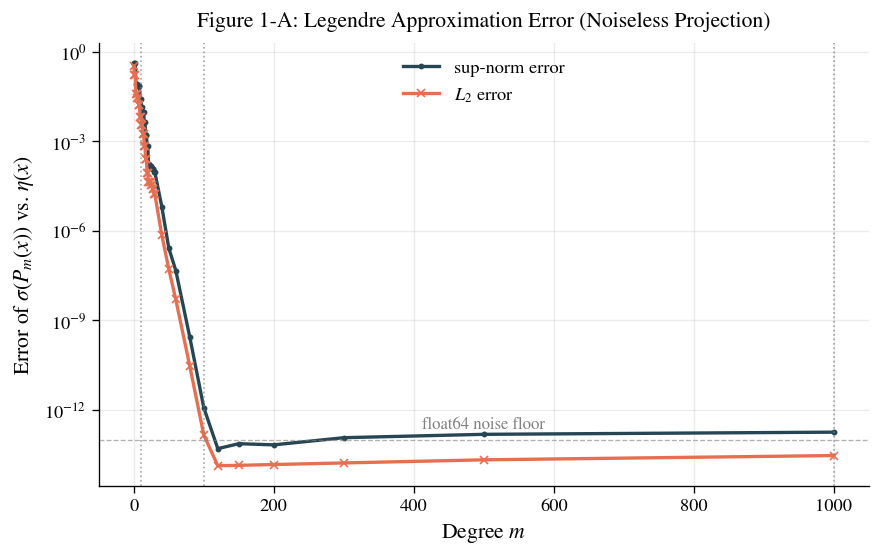

In [ ]:
fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.semilogy(m_grid_dense, sup_errs, color=PALETTE["eta"], lw=2.0, marker=".", markersize=5,
            label="sup-norm error")
ax.semilogy(m_grid_dense, l2_errs, color=PALETTE["train"], lw=2.0, marker="x", markersize=5,
            label=r"$L_2$ error")
for m in t1.PRIMARY_CAPACITIES:
    ax.axvline(m, color="gray", lw=1.0, ls=":", alpha=0.7)
ax.axhline(1e-13, color="gray", lw=0.8, ls="--", alpha=0.6)
ax.text(500, 2.5e-13, "float64 noise floor", fontsize=10, color="gray", ha="center")
ax.set_xlabel("Degree $m$", labelpad=4)
ax.set_ylabel(r"Error of $\sigma(P_m(x))$ vs. $\eta(x)$", labelpad=5)
ax.yaxis.set_major_locator(LogLocator(base=10, numticks=6))
ax.set_title("Figure 1-A: Legendre Approximation Error (Noiseless Projection)", pad=10)
ax.legend(frameon=False, loc="best")
ax.tick_params(axis="both", which="major", length=4, width=0.8)
fig.tight_layout()

fig.savefig("Figure_1A_legendre_approximation_error.pdf", format="pdf", bbox_inches="tight")
plt.show()

### Interpretation of Figure 1-A

- The approximation error decreases rapidly with polynomial degree, convergence is **spectral** (roughly geometric in $m$).

- At $m=10$, (the under-parameterised primary point), there is genuine,non-negligible approximation bias: sup-norm error $\approx 0.026$, $L_2$ error $\approx 0.0066$. Any miscalibration observed at $m=10$ in later notebooks could partly reflect this basis-truncation bias, not only estimation variance or overfitting.

- By $m=100$, the projection error is at numerical precision, indistinguishable from float64 noise. Thus, the two larger primary capacities (**$m=100$ and $m=1000$**) are therefore firmly in the "bias≈0" regime — the model class can represent $\eta(x)$ essentially exactly at these capacities. Any miscalibration error seen later are unlikely to be caused by polynomial approximation alone.